Spectrum Analyzer Measurements
==============================

This notebook contains code for plotting the time-domain pulse response as measured with the fancy spectrum analyzer we had access to. We had to use a spectrum analyzer, which is fundamentally a frequency-domain instrument instead of an oscilloscope since we did not have access to a sufficiently fast oscilloscope. An oscilloscope works in the time domain and would be naturally suited for risetime calculations.

To make up for this, we had to convert the spectrum measurements back from the frequency domain into the time domain through an inverse fourier transform. This isn't too bad, since our spectrum analyzer was a pretty nice one that had plenty of resolution and frequency headroom so numerical accuracy isn't a problem. In the end, for the measurement results this transform doesn't really matter since both time-domain and frequency-domain representations are equivalent anyway.

Imports and setup stuff
-----------------------

The following cells contain code loading the measurement data from CSV files exported by the spectrum analyzer.

In [2]:
import numpy as np
from scipy import fft
from scipy import signal as sig
from scipy import interpolate as interp
from io import StringIO
from matplotlib import pyplot as plt
%matplotlib inline

In [3]:
def load_keysight_csv(fn):
    with open(fn, 'r') as f:
        header = {}
        while (line := f.readline().strip()) != 'DATA':
            if ',' in line:
                key, _, value = line.partition(',')
                header[key] = value
        data = f.read()
        data = np.genfromtxt(StringIO(data), delimiter=',')
        return header, data

Initial plotting experiments
----------------------------

The cells below contain some initial experiments l

Fundamental peak: 7996500.0 -27.0907135009766
Frequency spacing is 49.973751 kHz
3 dB frequency from spline: 0.530 GHz, equiv t_r = 0.660 ns
Reconstruction sample spacing: 0.025 ns
edge 4985:5009: t_r=0.600 ns, equiv f_3dB = 0.583 GHz


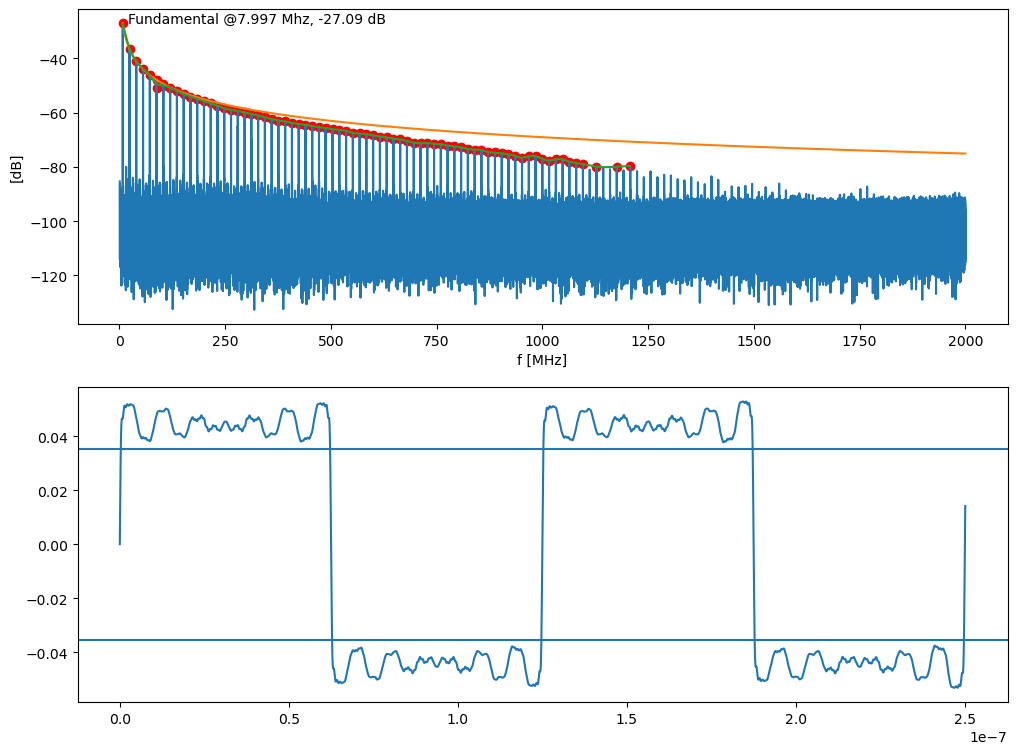

In [4]:
def plot_freq(fn):
    header_amp, data_amp = load_keysight_csv(fn)
    freq = data_amp[:,0]
    amp = data_amp[:,1]
    start_freq = float(header_amp['Start Frequency'])
    stop_freq = float(header_amp['Stop Frequency'])
    freq_spacing = (stop_freq - start_freq) / float(header_amp['Number of Points'])
    
    peaks, props = sig.find_peaks(amp, threshold=40)
    fundamental_idx = peaks[0]
    print('Fundamental peak:', freq[fundamental_idx], amp[fundamental_idx])
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))
    ax1.plot(freq/1e6, amp)
    ax1.set_xlabel('f [MHz]')
    ax1.set_ylabel('[dB]')
    ax1.annotate(f'Fundamental @{freq[fundamental_idx]/1e6:.3f} Mhz, {amp[fundamental_idx]:.2f} dB',
                (freq[fundamental_idx]/1e6, amp[fundamental_idx]),
                xytext=(5, 0),
                xycoords='data',
                textcoords='offset pixels',
               )
    
    freq_space = np.linspace(freq[fundamental_idx], stop_freq, 1000)
    sq_amp = np.sqrt(10**(amp[fundamental_idx]/10))
    sq_approx = 10*np.log10((sq_amp / (freq_space/freq[fundamental_idx]))**2)
    ax1.plot(freq_space/1e6, sq_approx)

    print(f'Frequency spacing is {freq_spacing/1e3:.6f} kHz')

    peaks, props = sig.find_peaks(amp, threshold=20, prominence=40, )
    peaks = [idx for idx in peaks if amp[idx] - 10*np.log10((sq_amp / (freq[idx]/freq[fundamental_idx]))**2) > -10]
    peak_freq = freq[peaks]
    peak_amp = amp[peaks]
    spl = interp.make_smoothing_spline(peak_freq, peak_amp, lam=1e20)
    ax1.scatter(peak_freq/1e6, peak_amp, color='red')
    freq_space_cut = freq_space[:np.argmin(freq_space < max(peak_freq))]
    ax1.plot(freq_space_cut/1e6, spl(freq_space_cut))
    kc = [(freq[idx]/freq[fundamental_idx], np.sqrt(10**(amp[idx]/10))) for idx in peaks]

    idx_3db = np.argmin(abs(spl(freq_space_cut) - sq_approx[:len(freq_space_cut)]) < 3.00)
    print(f'3 dB frequency from spline: {freq_space[idx_3db]/1e9:.3f} GHz, equiv t_r = {0.35 / freq_space[idx_3db] * 1e9:.3f} ns')
    
    t = np.linspace(0, 2, 10000)
    ts = 1/freq[fundamental_idx]
    tf = t * ts
    td_data = 4/np.pi * sum(c * np.sin(2*np.pi*k*t) for k, c in kc)
    ax2.plot(tf, td_data)
    
    lvl_high = kc[0][1]*0.8
    lvl_low = kc[0][1]*-0.8
    ax2.axhline(lvl_low)
    ax2.axhline(lvl_high)
    print(f'Reconstruction sample spacing: {(tf[1]-tf[0])*1e9:.3f} ns')

    state = None
    edge_start, edge_end = None, None
    for i, (dp, dn) in enumerate(zip(td_data, td_data[1:])):
        if dp <= lvl_low and dn >= lvl_low:
            if state != 'edge':
                state = 'edge'
                edge_start = i
        elif dp <= lvl_high and dn >= lvl_high:
            if state == 'edge':
                edge_end = i
                tr = tf[edge_end]-tf[edge_start]
                print(f'edge {edge_start}:{edge_end}: t_r={tr*1e9:.3f} ns, equiv f_3dB = {0.35/tr/1e9:.3f} GHz')
            state = 'high'
        elif dp <= lvl_low and dn <= lvl_low:
            state = 'low'
        elif dp >= lvl_high and dn >= lvl_high:
            state = 'high'

    #fft_data = np.hstack([
    #    np.zeros(round(start_freq / freq_spacing)),
    #    10**(amp/20)])
    #fft_data = np.hstack([fft_data, fft_data[1::-1]])
    
    #time_domain_amp = fft.ifft(fft_data)
    
    #ax2.plot(time_domain_amp)
    #ax2.set_xlim([1000, 4000])
    #ax2.set_ylim([-0.5e-5, 0.5e-5])

plot_freq('../spectrum_measurements/amp_out_span_2g_rbw_10k_40kpt_0000.csv')

Fundamental peak: 7996500.0 -38.6481513977051
Frequency spacing is 49.973751 kHz
3 dB frequency from spline: 0.564 GHz, equiv t_r = 0.620 ns
Reconstruction sample spacing: 0.025 ns
edge 4985:5010: t_r=0.625 ns, equiv f_3dB = 0.560 GHz


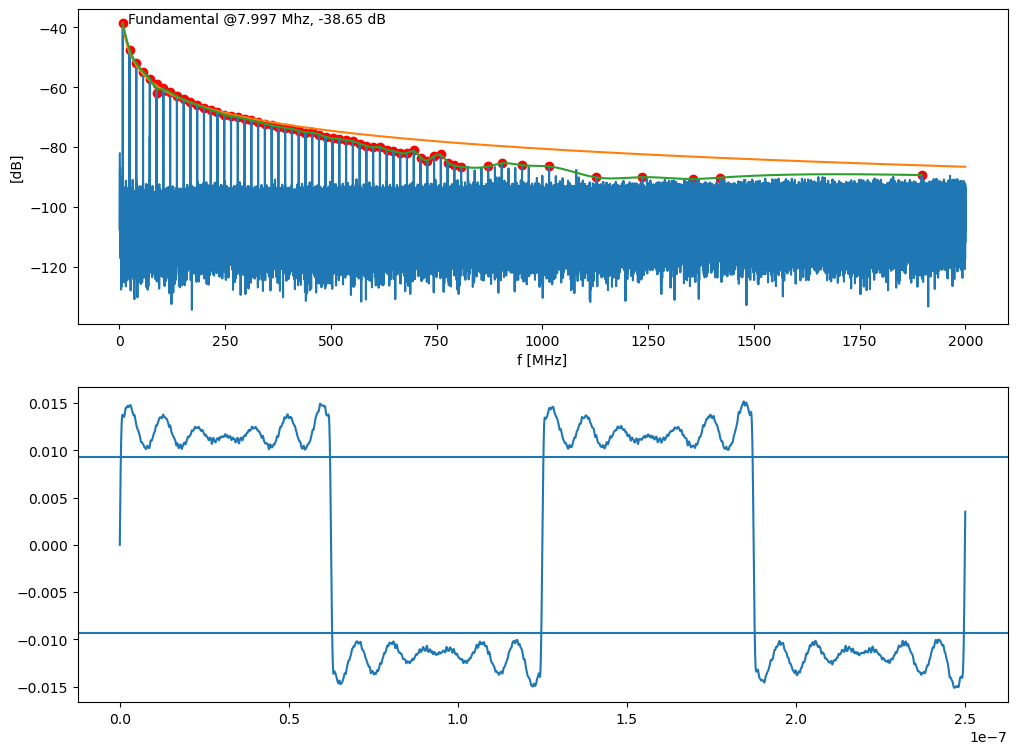

In [5]:
plot_freq('../spectrum_measurements/board_out_span_2g_rbw_10k_40kpt.csv')

Fundamental peak: 8009960.0 -25.7375087738037
Frequency spacing is 1997.992008 kHz
3 dB frequency from spline: 0.245 GHz, equiv t_r = 1.427 ns
Reconstruction sample spacing: 0.025 ns
edge 4995:5014: t_r=0.474 ns, equiv f_3dB = 0.738 GHz


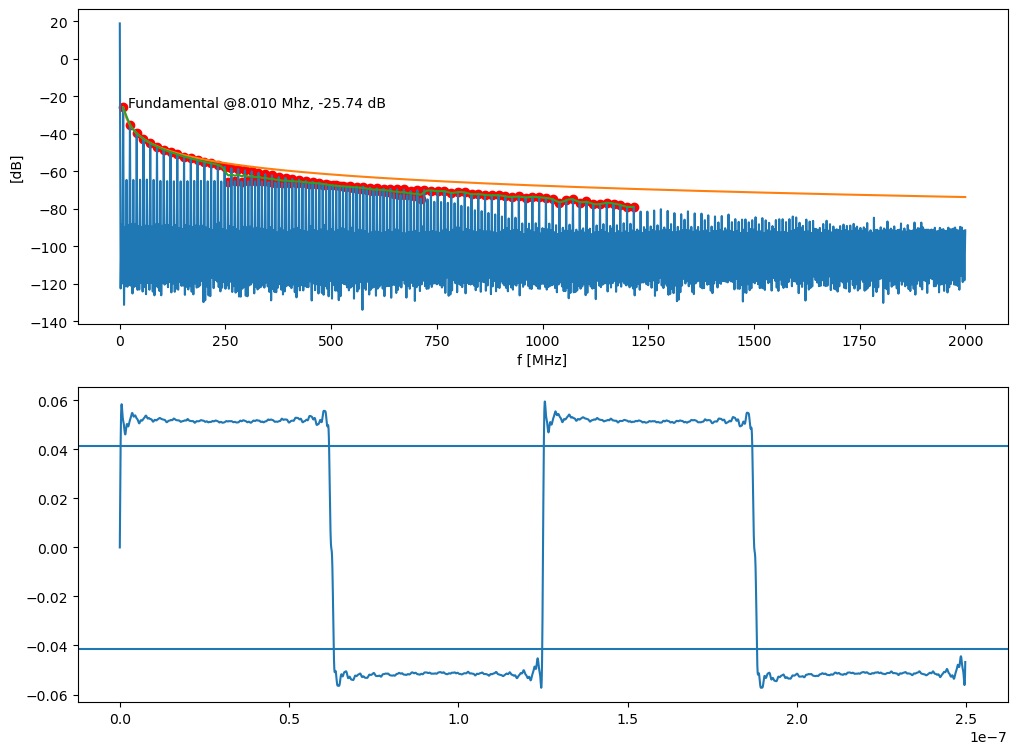

In [6]:
plot_freq('../data_spectrum/pi3hdx_bent_2.csv')

Fundamental peak: 88009780.0 -30.2440490722656


/usr/lib/python3.13/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/lib/python3.13/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


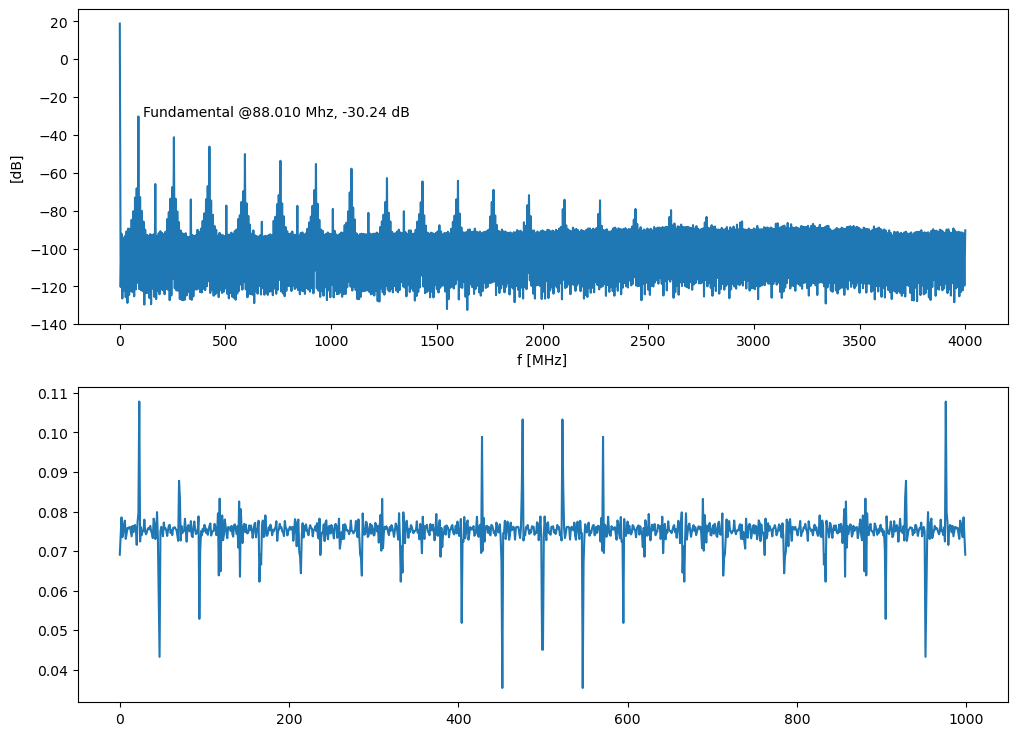

In [7]:
def plot_freq(fn):
    header_amp, data_amp = load_keysight_csv(fn)
    freq = data_amp[:,0]
    amp = data_amp[:,1]
    start_freq = float(header_amp['Start Frequency'])
    stop_freq = float(header_amp['Stop Frequency'])
    freq_spacing = (stop_freq - start_freq) / float(header_amp['Number of Points'])
    
    peaks, props = sig.find_peaks(amp, threshold=60)
    fundamental_idx = peaks[0]
    print('Fundamental peak:', freq[fundamental_idx], amp[fundamental_idx])
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))
    ax1.plot(freq/1e6, amp)
    ax1.set_xlabel('f [MHz]')
    ax1.set_ylabel('[dB]')
    ax1.annotate(f'Fundamental @{freq[fundamental_idx]/1e6:.3f} Mhz, {amp[fundamental_idx]:.2f} dB',
                (freq[fundamental_idx]/1e6, amp[fundamental_idx]),
                xytext=(5, 0),
                xycoords='data',
                textcoords='offset pixels',
               )

    amp[amp < -80] = 0
    sq_amp = 10**(amp/10)
    td_data = fft.ifft(sq_amp)
    ax2.plot(td_data[1:])

plot_freq('../data_spectrum/tdp0604_bent_3.csv')

Fundamental peak: 88009780.0 -30.2440490722656
Frequency spacing is 3995.994006 kHz
3 dB frequency from spline: 0.088 GHz, equiv t_r = 3.977 ns
Reconstruction sample spacing: 11.362 ns
edge 9852:10145: t_r=0.266 ns, equiv f_3dB = 1.314 GHz


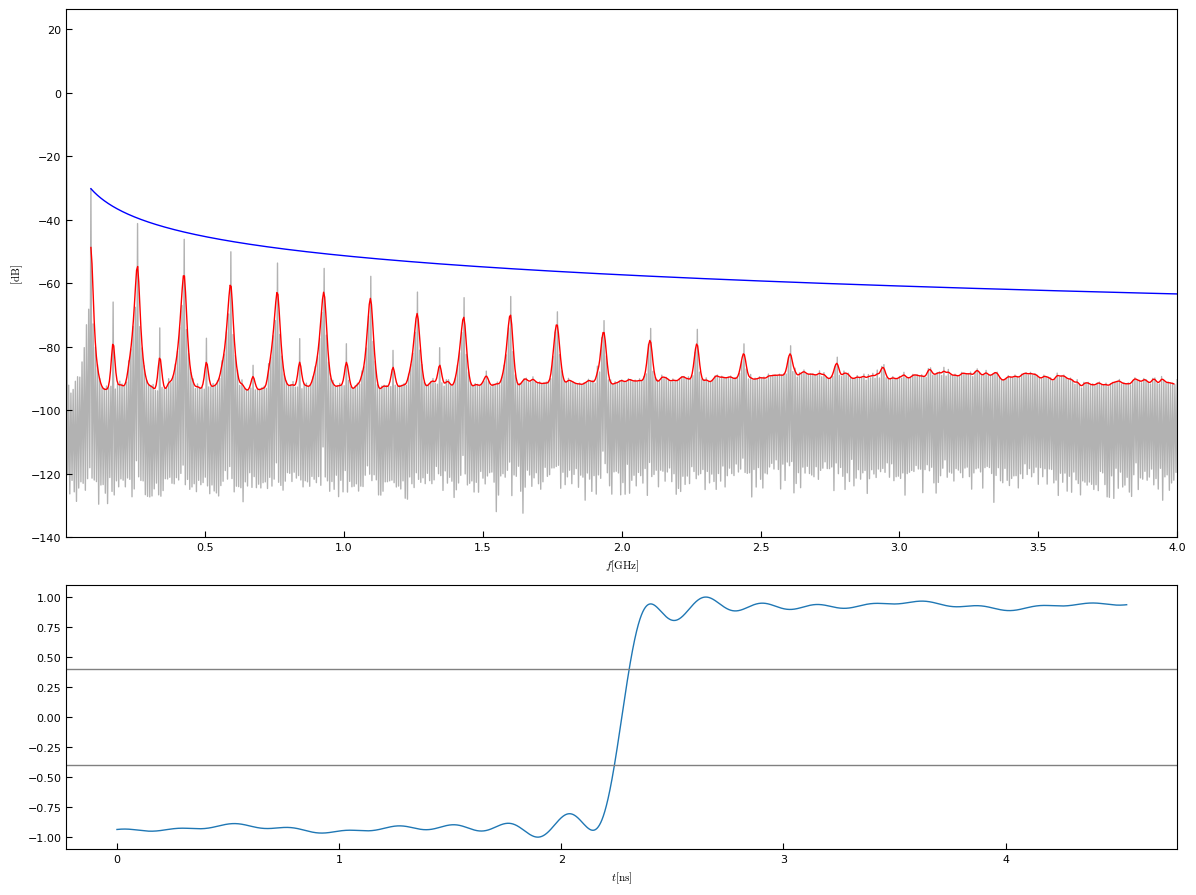

In [9]:
def plot_freq(fn):
    with plt.rc_context({
        'legend.fontsize': 8,
        # RC config from ChatGPT:
        "font.size": 8,  # General font size
        "axes.labelsize": 8,  # Axis labels
        "axes.titlesize": 8,  # Axis titles
        "xtick.labelsize": 8,  # X-axis tick labels
        "ytick.labelsize": 8,  # Y-axis tick labels
        "legend.fontsize": 8,  # Legend font size
        "figure.titlesize": 12,  # Overall figure title
        "mathtext.fontset": "cm",  # Use Computer Modern for math
    
        # Line and Marker settings
        "lines.linewidth": 1,
        "lines.markersize": 3,
    
        # Tick settings
        "xtick.major.size": 4,
        "xtick.minor.size": 2,
        "ytick.major.size": 4,
        "ytick.minor.size": 2,
        "xtick.direction": "in",
        "ytick.direction": "in",
    
        # Axes settings
        "axes.linewidth": 0.8,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
    
        # Legend settings
        "legend.frameon": False,
    
        # Figure size for single-column figures in print (inches)
    #    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
    #    "figure.dpi": 300,  # High resolution for print
    
        # Savefig settings for high-quality output
        "savefig.dpi": 600,  # Ensures high-resolution images
        "savefig.bbox": "tight",  # Trim extra whitespace
        "savefig.transparent": True,  # Avoid background color
    }):
        header_amp, data_amp = load_keysight_csv(fn)
        freq = data_amp[:,0]
        amp = data_amp[:,1]
        start_freq = float(header_amp['Start Frequency'])
        stop_freq = float(header_amp['Stop Frequency'])
        freq_spacing = (stop_freq - start_freq) / float(header_amp['Number of Points'])
        
        fundamental_idx = 1 + amp[1:].argmax()
        print('Fundamental peak:', freq[fundamental_idx], amp[fundamental_idx])
        
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw={'height_ratios': [2, 1]})
        ax1.plot(freq/1e9, amp, color='black', alpha=0.3)
        ax1.set_xlabel(r'$f [\mathrm{GHz}]$')
        ax1.set_ylabel(r'$[\mathrm{dB}]$')
        #ax1.annotate(f'Fundamental @{freq[fundamental_idx]/1e6:.3f} Mhz, {amp[fundamental_idx]:.2f} dB',
        #            (freq[fundamental_idx]/1e6, amp[fundamental_idx]),
        #            xytext=(5, 0),
        #            xycoords='data',
        #            textcoords='offset pixels',
        #           )
        
        freq_space = np.linspace(freq[fundamental_idx], stop_freq, 1000)
        sq_amp = np.sqrt(10**(amp[fundamental_idx]/10))
        sq_approx = 10*np.log10((sq_amp / (freq_space/freq[fundamental_idx]))**2)
        ax1.plot(freq_space/1e9, sq_approx, color='blue')
    
        print(f'Frequency spacing is {freq_spacing/1e3:.6f} kHz')
    
        peaks, _props = sig.find_peaks(amp, prominence=20)
        peaks = [idx for idx in peaks]
                #if amp[idx] - 10*np.log10((sq_amp / (freq[idx]/freq[fundamental_idx]))**2) > -10]
                #and abs((freq[idx] / freq[fundamental_idx]) % 1.0 - 0.5) > 0.4]
        peak_freq = freq[peaks]
        peak_amp = amp[peaks]
        spl = interp.make_smoothing_spline(peak_freq, peak_amp, lam=1e20)
        #ax1.scatter(peak_freq/1e6, peak_amp, color='red')
        freq_space_cut = freq_space[:np.argmin(freq_space < max(peak_freq))]
        ax1.plot(freq_space_cut/1e9, spl(freq_space_cut), color='red')
        kc = [(freq[idx]/freq[fundamental_idx], np.sqrt(10**(amp[idx]/10))) for idx in peaks]
    
        idx_3db = np.argmin(abs(spl(freq_space_cut) - sq_approx[:len(freq_space_cut)]) < 3.00)
        print(f'3 dB frequency from spline: {freq_space[idx_3db]/1e9:.3f} GHz, equiv t_r = {0.35 / freq_space[idx_3db] * 1e9:.3f} ns')
    
        plot_width = 0.2
        t = np.linspace(0, plot_width, 10000)
        ts = 1/freq[fundamental_idx]
        tf = t * ts
        td_data = 4/np.pi * sum(c * np.sin(2*np.pi*k*t) for k, c in kc)
        #td_data = fft.ifft([c for k, c in kc])
        td_data = np.hstack([-td_data[::-1], td_data[1:]])
        lvl_low = td_data.min()
        lvl_high = td_data.max()
        lvl_amp = lvl_high - lvl_low
        td_data = -1 + (td_data - lvl_low) / lvl_amp * 2
        ax2.plot(np.linspace(0, 2*plot_width*ts*1e9, 10000*2-1), td_data)
        
        lvl_low = -0.4
        lvl_high = 0.4
        ax2.axhline(lvl_low, color='gray')
        ax2.axhline(lvl_high, color='gray')
        ax2.grid()
        ax1.grid()
        ax1.set_xlim([start_freq/1e9, stop_freq/1e9])
        ax2.set_xlabel(r'$t [\mathrm{ns}]$')
        print(f'Reconstruction sample spacing: {ts*1e9:.3f} ns')
    
        state = None
        edge_start, edge_end = None, None
        for i, (dp, dn) in enumerate(zip(td_data, td_data[1:])):
            if dp <= lvl_low and dn >= lvl_low:
                if state != 'edge':
                    state = 'edge'
                    edge_start = i
            elif dp <= lvl_high and dn >= lvl_high:
                if state == 'edge':
                    edge_end = i
                    tr = 0.4*2*ts/10000*(edge_end-edge_start)
                    print(f'edge {edge_start}:{edge_end}: t_r={tr*1e9:.3f} ns, equiv f_3dB = {0.35/tr/1e9:.3f} GHz')
                state = 'high'
            elif dp <= lvl_low and dn <= lvl_low:
                state = 'low'
            elif dp >= lvl_high and dn >= lvl_high:
                state = 'high'
    
        #fft_data = np.hstack([
        #    np.zeros(round(start_freq / freq_spacing)),
        #    10**(amp/20)])
        #fft_data = np.hstack([fft_data, fft_data[1::-1]])
        
        #time_domain_amp = fft.ifft(fft_data)
        
        #ax2.plot(time_domain_amp)
        #ax2.set_xlim([1000, 4000])
        #ax2.set_ylim([-0.5e-5, 0.5e-5])
        fig.tight_layout()

plot_freq('../data_spectrum/tdp0604_bent_3.csv')

Fundamental peak: 88009780.0 -30.2440490722656
Frequency spacing is 3995.994006 kHz
Reconstruction sample spacing: 11.362 ns
edge 9736:10261: t_r=0.119 ns, equiv f_3dB = 2.934 GHz


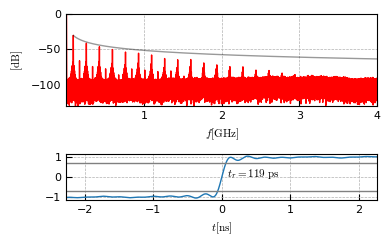

In [11]:
def plot_freq(fn):
    with plt.rc_context({
        'legend.fontsize': 8,
        # RC config from ChatGPT:
        "font.size": 8,  # General font size
        "axes.labelsize": 8,  # Axis labels
        "axes.titlesize": 8,  # Axis titles
        "xtick.labelsize": 8,  # X-axis tick labels
        "ytick.labelsize": 8,  # Y-axis tick labels
        "legend.fontsize": 8,  # Legend font size
        "figure.titlesize": 12,  # Overall figure title
        "mathtext.fontset": "cm",  # Use Computer Modern for math
    
        # Line and Marker settings
        "lines.linewidth": 1,
        "lines.markersize": 3,
    
        # Tick settings
        "xtick.major.size": 4,
        "xtick.minor.size": 2,
        "ytick.major.size": 4,
        "ytick.minor.size": 2,
        "xtick.direction": "in",
        "ytick.direction": "in",
    
        # Axes settings
        "axes.linewidth": 0.8,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
    
        # Legend settings
        "legend.frameon": False,
    
        # Figure size for single-column figures in print (inches)
    #    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
    #    "figure.dpi": 300,  # High resolution for print
    
        # Savefig settings for high-quality output
        "savefig.dpi": 600,  # Ensures high-resolution images
        "savefig.bbox": "tight",  # Trim extra whitespace
        "savefig.transparent": True,  # Avoid background color
    }):
        header_amp, data_amp = load_keysight_csv(fn)
        freq = data_amp[:,0]
        amp = data_amp[:,1]
        start_freq = float(header_amp['Start Frequency'])
        stop_freq = float(header_amp['Stop Frequency'])
        freq_spacing = (stop_freq - start_freq) / float(header_amp['Number of Points'])
        
        fundamental_idx = 1 + amp[1:].argmax()
        print('Fundamental peak:', freq[fundamental_idx], amp[fundamental_idx])
        
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 2.5), gridspec_kw={'height_ratios': [2, 1]})
        ax1.plot(freq/1e9, amp, color='red', alpha=1.0)
        ax1.set_xlabel(r'$f [\mathrm{GHz}]$')
        ax1.set_ylabel(r'$[\mathrm{dB}]$')
        #ax1.annotate(f'Fundamental @{freq[fundamental_idx]/1e6:.3f} Mhz, {amp[fundamental_idx]:.2f} dB',
        #            (freq[fundamental_idx]/1e6, amp[fundamental_idx]),
        #            xytext=(5, 0),
        #            xycoords='data',
        #            textcoords='offset pixels',
        #           )
        
        freq_space = np.linspace(freq[fundamental_idx], stop_freq, 1000)
        sq_amp = np.sqrt(10**(amp[fundamental_idx]/10))
        sq_approx = 10*np.log10((sq_amp / (freq_space/freq[fundamental_idx]))**2)
        ax1.plot(freq_space/1e9, sq_approx, color='black', alpha=0.4)
    
        print(f'Frequency spacing is {freq_spacing/1e3:.6f} kHz')

        kc = zip(freq/freq[fundamental_idx], np.sqrt(10**(amp/10)))
        plot_width = .2
        t = np.linspace(0, plot_width, 10000)
        ts = 1/freq[fundamental_idx]
        tf = t * ts
        td_data = 4/np.pi * sum(c * np.sin(2*np.pi*k*t) for k, c in kc)
        #td_data = fft.ifft([c for k, c in kc])
        td_data = np.hstack([-td_data[::-1], td_data[1:]])
        td_data_sort = np.array(sorted(td_data))
        lvl_low = td_data_sort[:len(td_data_sort)//5].max()
        lvl_high = td_data_sort[-len(td_data_sort)//5:].min()
        lvl_amp = lvl_high - lvl_low
        td_data = -1 + (td_data - lvl_low) / lvl_amp * 2
        ax2.plot(np.linspace(-plot_width*ts*1e9, plot_width*ts*1e9, 10000*2-1), td_data)
        ax2.set_xlim([-plot_width*ts*1e9, plot_width*ts*1e9])
        
        lvl_low = -0.7
        lvl_high = 0.7
        ax2.axhline(lvl_low, color='gray')
        ax2.axhline(lvl_high, color='gray')
        ax1.set_xlim([start_freq/1e9, stop_freq/1e9])
        ax2.set_xlabel(r'$t [\mathrm{ns}]$')
        ax1.set_ylim([-130, 0])
        print(f'Reconstruction sample spacing: {ts*1e9:.3f} ns')
        
        state = None
        edge_start, edge_end = None, None
        for i, (dp, dn) in enumerate(zip(td_data, td_data[1:])):
            if dp <= lvl_low and dn >= lvl_low:
                if state != 'edge':
                    state = 'edge'
                    edge_start = i
            elif dp <= lvl_high and dn >= lvl_high:
                if state == 'edge':
                    edge_end = i
                    tr = plot_width*ts/10000*(edge_end-edge_start)
                    print(f'edge {edge_start}:{edge_end}: t_r={tr*1e9:.3f} ns, equiv f_3dB = {0.35/tr/1e9:.3f} GHz')
                    break
                state = 'high'
            elif dp <= lvl_low and dn <= lvl_low:
                state = 'low'
            elif dp >= lvl_high and dn >= lvl_high:
                state = 'high'

        tr_scaled, prefix = tr*1e9, 'n'
        if tr_scaled < 1:
            tr_scaled, prefix = tr*1e12, 'p'
        ax2.annotate(fr'$t_r = {tr_scaled:3.0f}\;\mathrm{{{prefix}s}}$',
                    (0, 0),
                    xytext=(5, 0),
                    xycoords='data',
                    textcoords='offset pixels',
                   )
        
        #fft_data = np.hstack([
        #    np.zeros(round(start_freq / freq_spacing)),
        #    10**(amp/20)])
        #fft_data = np.hstack([fft_data, fft_data[1::-1]])
        
        #time_domain_amp = fft.ifft(fft_data)
        
        #ax2.plot(time_domain_amp)
        #ax2.set_xlim([1000, 4000])
        #ax2.set_ylim([-0.5e-5, 0.5e-5])
        fig.tight_layout()
        return fig

plot_freq('../data_spectrum/tdp0604_bent_3.csv').savefig('../../paper/fig_spec_risetime_tdp0604.pdf')

Fundamental peak: 88009780.0 -26.0266227722168
Frequency spacing is 3995.994006 kHz
Reconstruction sample spacing: 11.362 ns
edge 9579:10418: t_r=0.191 ns, equiv f_3dB = 1.836 GHz


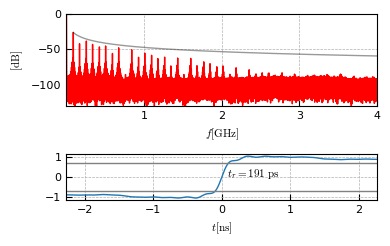

In [12]:
plot_freq('../data_spectrum/pi3hdx_bent_3.csv').savefig('../../paper/fig_spec_risetime_pi3hdx.pdf')

Fundamental peak: 88009780.0 -31.5218181610107
Frequency spacing is 3995.994006 kHz
Reconstruction sample spacing: 11.362 ns
edge 9722:10274: t_r=0.125 ns, equiv f_3dB = 2.790 GHz


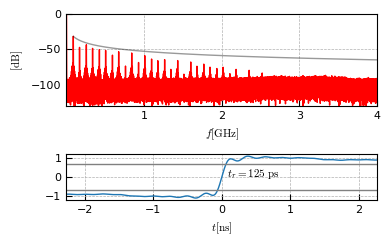

In [13]:
plot_freq('../data_spectrum/max3748_bent_3.csv').savefig('../../paper/fig_spec_risetime_max3748.pdf')

Fundamental peak: 88009780.0 -15.3417797088623
Frequency spacing is 3995.994006 kHz
Reconstruction sample spacing: 11.362 ns
edge 8738:11259: t_r=0.573 ns, equiv f_3dB = 0.611 GHz


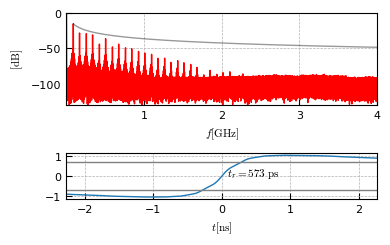

In [14]:
plot_freq('../data_spectrum/74lvc_bent_3.csv').savefig('../../paper/fig_spec_risetime_74lvc.pdf')